# **Análisis de factores de Detracción en el Campus Distancia**

**Importar paquetes**

In [1]:
import pandas as pd
import os
import sys
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, confusion_matrix
import seaborn as sns

**Preparación del acceso al Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


# Get the current directory of the notebook
current_dir = os.getcwd()

# Construct the path to the utilidadesML directory (assuming it's in the same directory as the notebook)
utilidadesML_path = os.path.join(current_dir, "drive/MyDrive/Colab Notebooks")

# Add the utilidadesML directory to the Python path
sys.path.append(utilidadesML_path)

import utilidadesML as ml

Mounted at /content/drive


**Lectura de los datos**

In [3]:
from google.colab import drive
drive.mount('/content/drive')
estudiantes = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DATANPS2025.csv', sep=";")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Análisis de correlaciones para Detractores**

In [13]:
estudiantes_DISTANCIA = estudiantes[estudiantes['X_CAMPUS'] == 'VIR'].copy()
estudiantes_DISTANCIA.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1422 entries, 4 to 7908
Data columns (total 76 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_COD                 1422 non-null   int64  
 1   ID                     1422 non-null   int64  
 2   X_CAMPUS               1422 non-null   object 
 3   X_PERIODO              1422 non-null   object 
 4   X_MODALIDAD            1422 non-null   object 
 5   PROGRAMA               1422 non-null   int64  
 6   X_FACULTAD             1422 non-null   object 
 7   DESCRIPCION_PROGRAMA   1422 non-null   object 
 8   PERIODO_ADMISION       1422 non-null   int64  
 9   CATALOGO               1422 non-null   int64  
 10  CICLO_ACTUAL           1422 non-null   int64  
 11  CREDITOS_TOTAL         1422 non-null   int64  
 12  CREDITOS_MATRICULADOS  1422 non-null   int64  
 13  CACHIMBO               1422 non-null   int64  
 14  REINCORPORADO          1422 non-null   int64  
 15  TRASLADOS

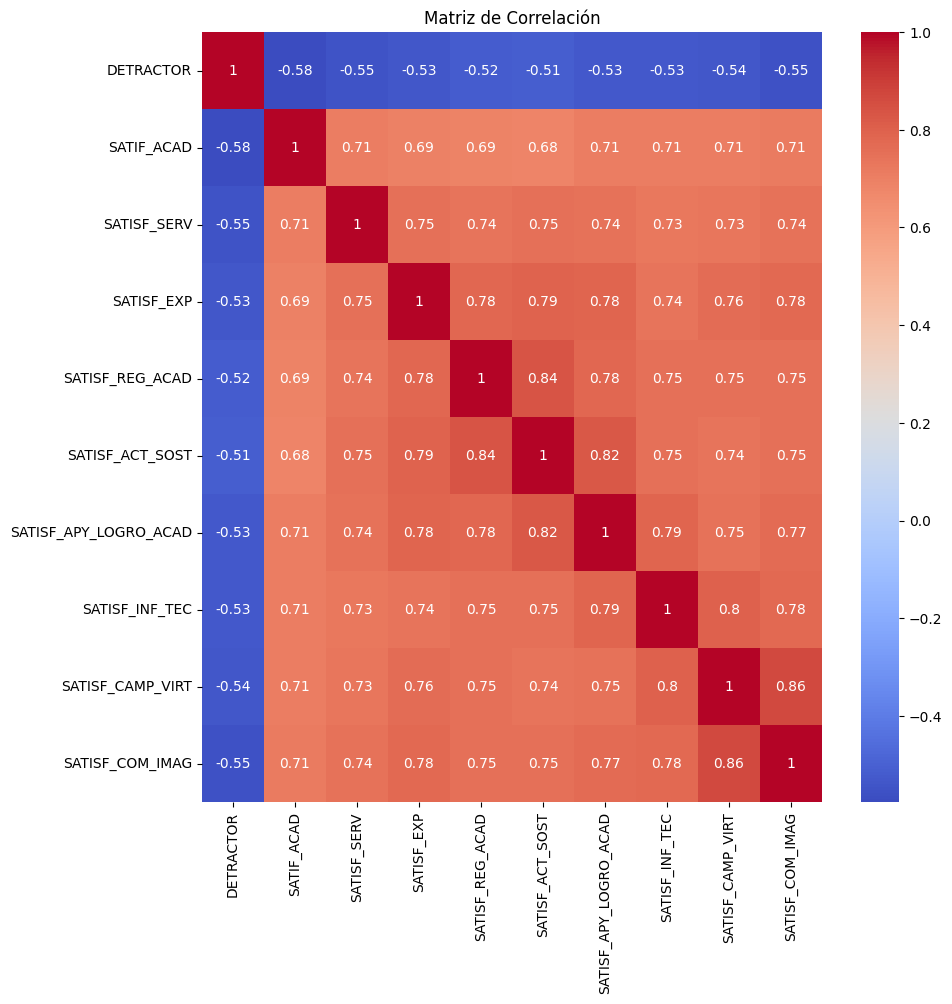

In [14]:
copia = X = estudiantes_DISTANCIA[['DETRACTOR', 'SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
plt.figure(figsize=(10, 10))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

**Preparación de conjuntos de extrenamiento y testing**

In [15]:
X = estudiantes_DISTANCIA[['SATIF_ACAD', 'SATISF_SERV', 'SATISF_EXP', 'SATISF_REG_ACAD', 'SATISF_ACT_SOST', 'SATISF_APY_LOGRO_ACAD', 'SATISF_INF_TEC', 'SATISF_CAMP_VIRT', 'SATISF_COM_IMAG']]
y = estudiantes_DISTANCIA['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

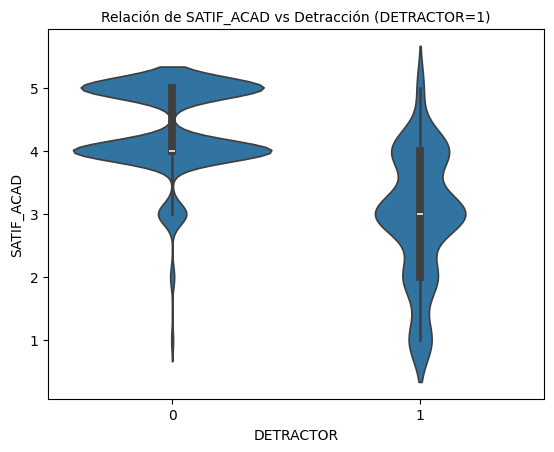

*** Prueba t para SATIF_ACAD ***
Estadístico t: -26.54955
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.339880
1    2.956175
Name: SATIF_ACAD, dtype: float64




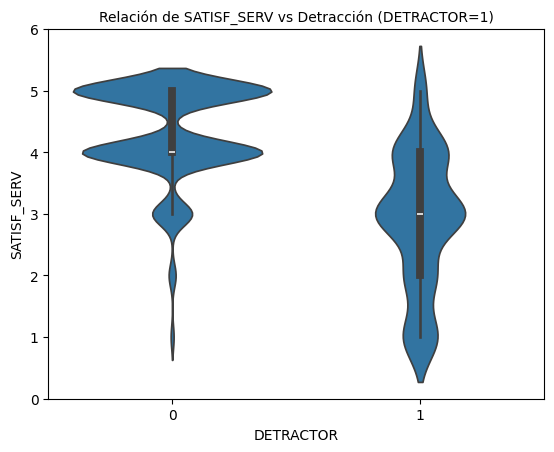

*** Prueba t para SATISF_SERV ***
Estadístico t: -24.52204
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.316823
1    2.896414
Name: SATISF_SERV, dtype: float64




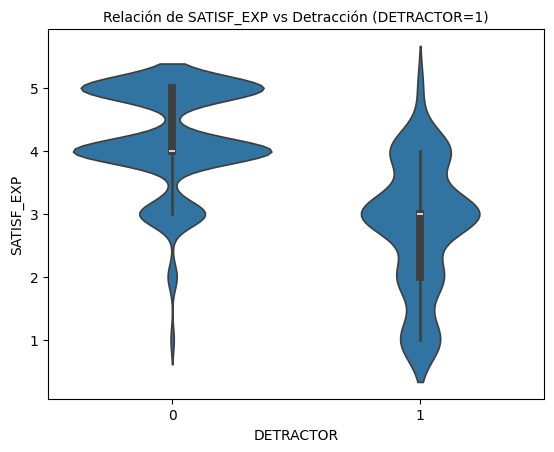

*** Prueba t para SATISF_EXP ***
Estadístico t: -23.82705
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.194705
1    2.796813
Name: SATISF_EXP, dtype: float64




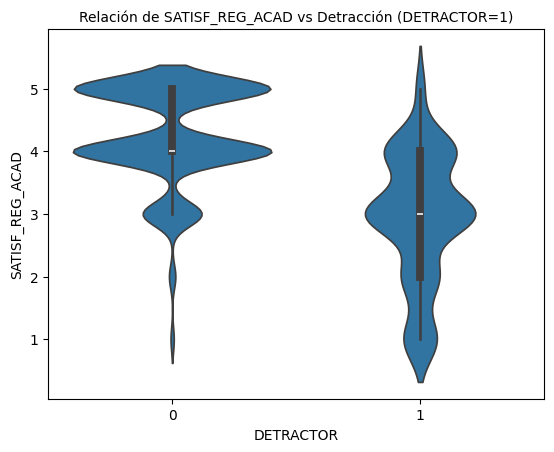

*** Prueba t para SATISF_REG_ACAD ***
Estadístico t: -22.72462
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.248506
1    2.940239
Name: SATISF_REG_ACAD, dtype: float64




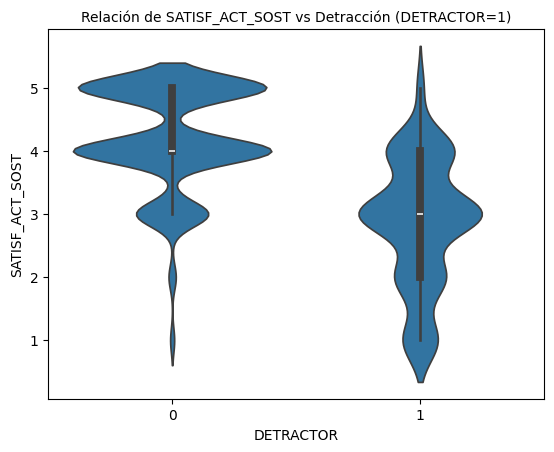

*** Prueba t para SATISF_ACT_SOST ***
Estadístico t: -22.59619
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.190436
1    2.860558
Name: SATISF_ACT_SOST, dtype: float64




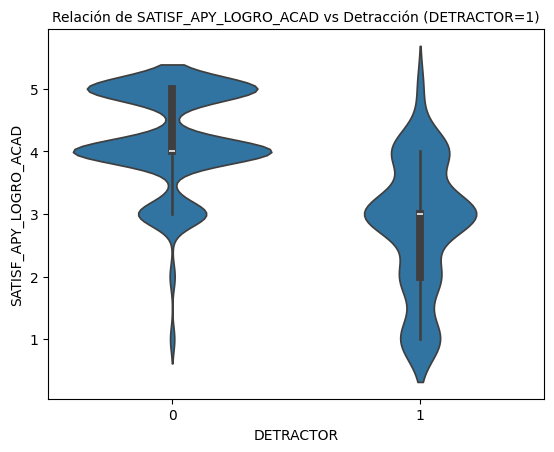

*** Prueba t para SATISF_APY_LOGRO_ACAD ***
Estadístico t: -23.53513
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.178480
1    2.800797
Name: SATISF_APY_LOGRO_ACAD, dtype: float64




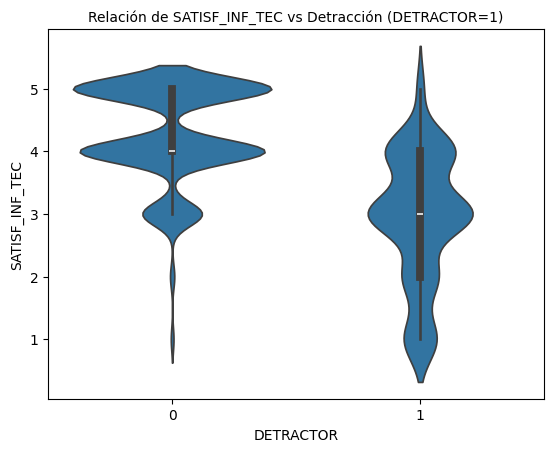

*** Prueba t para SATISF_INF_TEC ***
Estadístico t: -23.53239
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.271563
1    2.928287
Name: SATISF_INF_TEC, dtype: float64




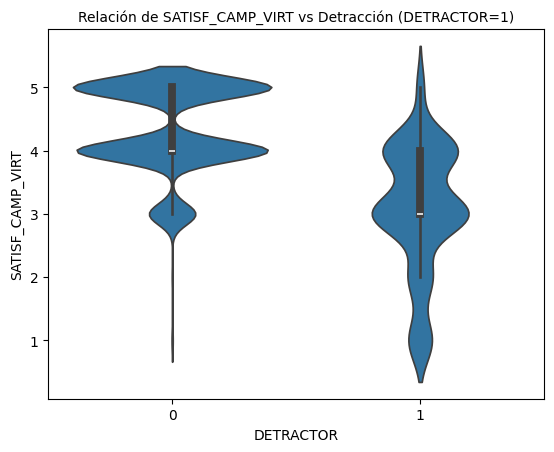

*** Prueba t para SATISF_CAMP_VIRT ***
Estadístico t: -24.03367
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.335611
1    3.079681
Name: SATISF_CAMP_VIRT, dtype: float64




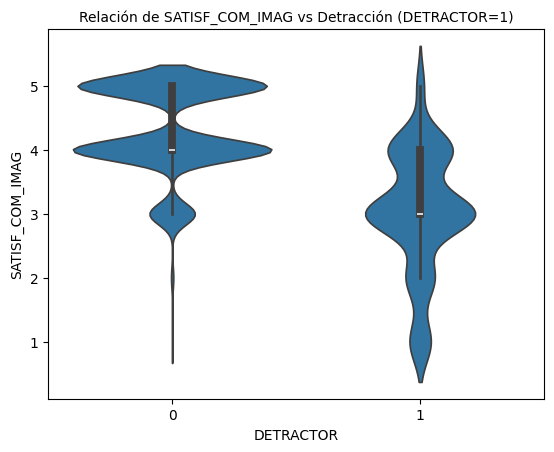

*** Prueba t para SATISF_COM_IMAG ***
Estadístico t: -25.00713
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.316823
1    3.035857
Name: SATISF_COM_IMAG, dtype: float64




In [16]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_DISTANCIA, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_DISTANCIA, 'DETRACTOR', column, 1, 0, XCopia)

**Modelo de Regresión Logística para predecir Detractores**

Precisión del modelo con class_weight='balanced': 0.849
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.94      0.87      0.91       239
           1       0.52      0.72      0.61        46

    accuracy                           0.85       285
   macro avg       0.73      0.80      0.76       285
weighted avg       0.87      0.85      0.86       285



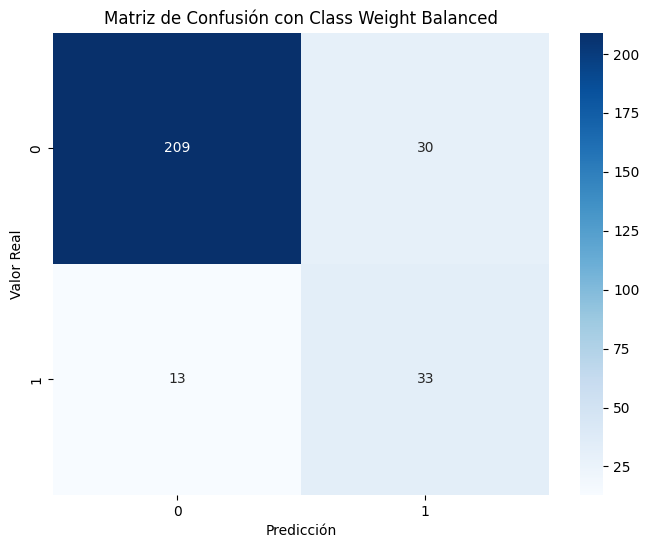

In [17]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.20, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

### **Análisis de la Importancia de las Variables (`model_balanced`)**

SATIF_ACAD: -0.82
SATISF_SERV: -0.31
SATISF_EXP: -0.34
SATISF_REG_ACAD: -0.02
SATISF_ACT_SOST: -0.17
SATISF_APY_LOGRO_ACAD: -0.21
SATISF_INF_TEC: -0.10
SATISF_CAMP_VIRT: 0.08
SATISF_COM_IMAG: -0.27


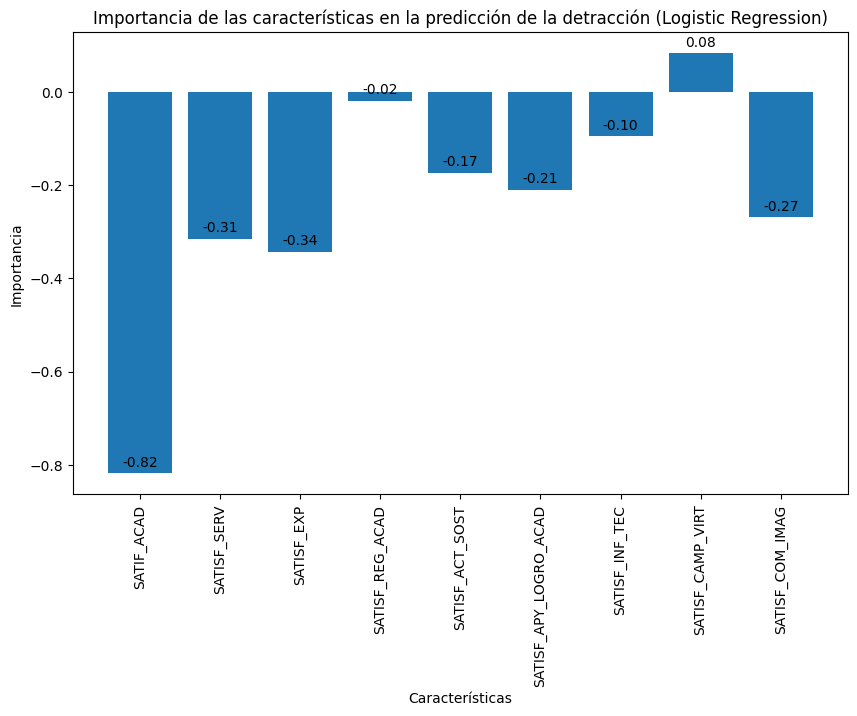

In [18]:
feature_importance = model_balanced.coef_[0]

for i in range(0, len(XCopia.columns)):
    print(f"{XCopia.columns[i]}: {feature_importance[i]:.2f}")

plt.figure(figsize=(10, 6))
bars = plt.bar(XCopia.columns, feature_importance)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en la predicción de la detracción (Logistic Regression)')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.xticks(rotation=90)
plt.show()

### **Análisis SHAP para `model_balanced`**

  0%|          | 0/285 [00:00<?, ?it/s]

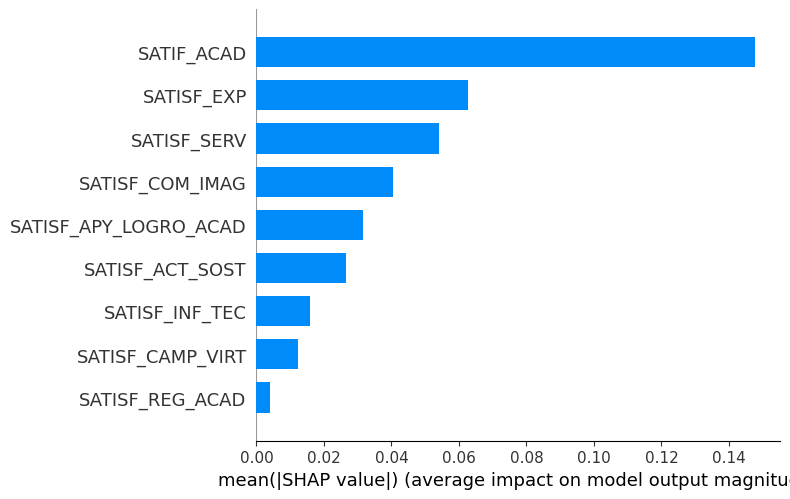

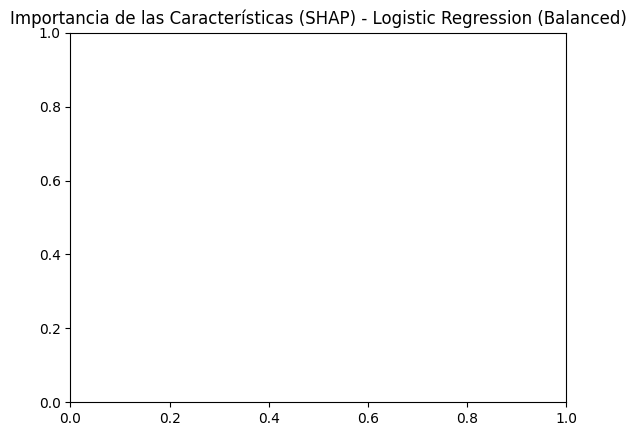

In [19]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Análisis de Deep Learning para ver impacto de las variables en el modelo**

  0%|          | 0/285 [00:00<?, ?it/s]

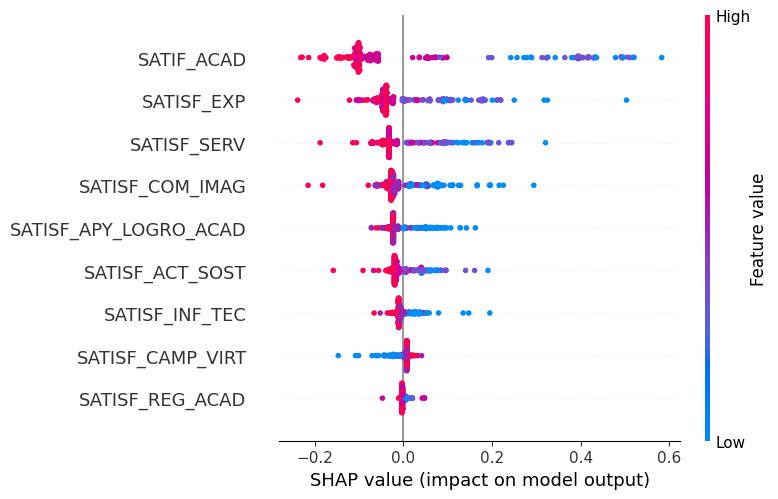

In [20]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción lo académico**
**P3. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON EL ÁREA ACADÉMICA DE LA UNIVERSIDAD CONTINENTAL?**

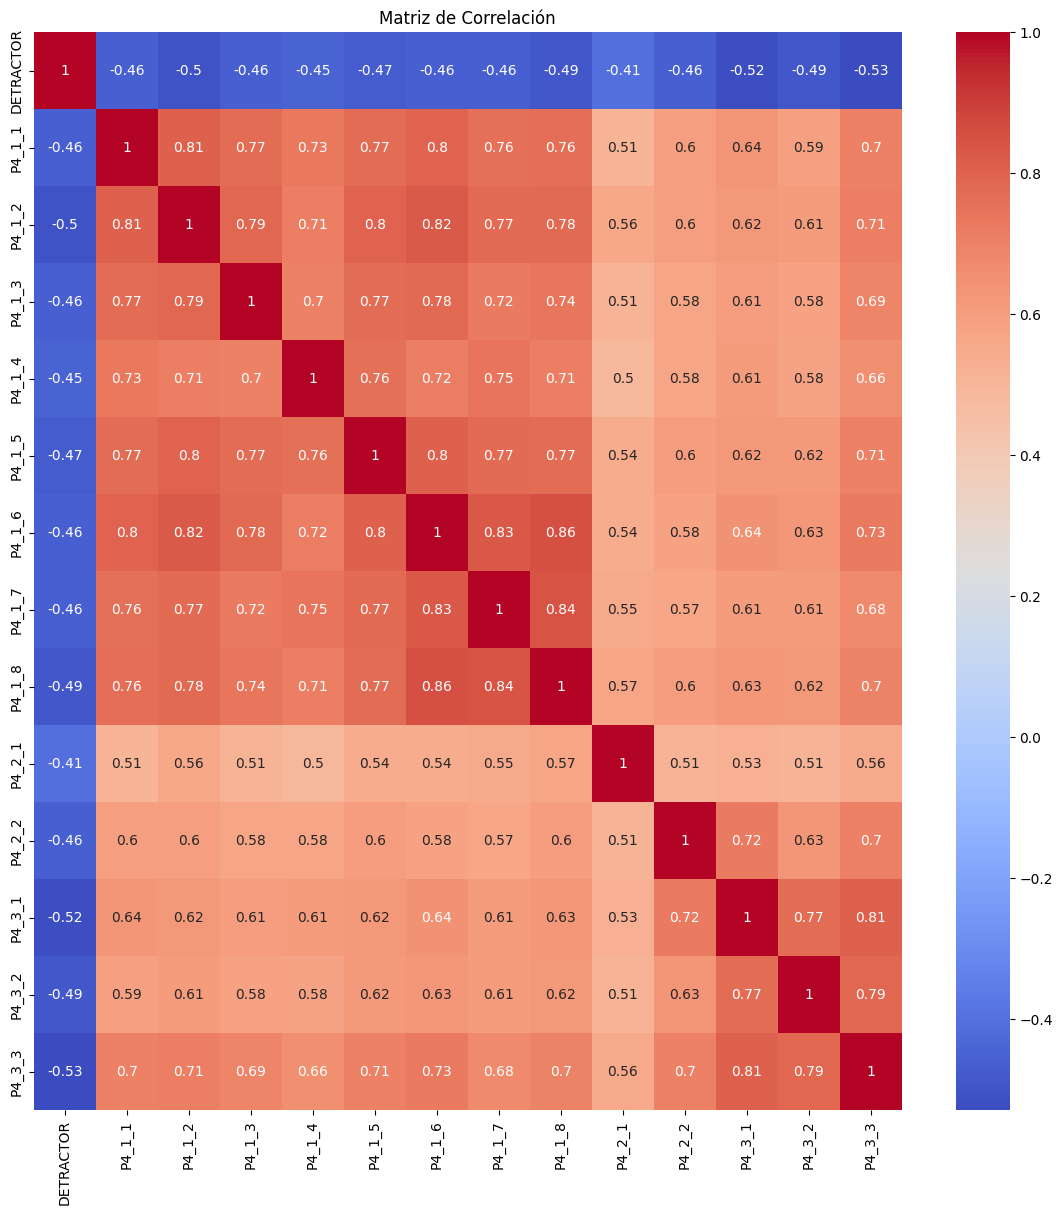

In [21]:
copia = X = estudiantes_DISTANCIA[['DETRACTOR','P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
plt.figure(figsize=(14, 14))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [22]:
X = estudiantes_DISTANCIA[['P4_1_1','P4_1_2','P4_1_3','P4_1_4','P4_1_5','P4_1_6','P4_1_7','P4_1_8','P4_2_1','P4_2_2','P4_3_1','P4_3_2','P4_3_3']]
y = estudiantes_DISTANCIA['DETRACTOR']
XCopia = X.copy()

**Pruebas T de Diferencia de Medias para refinar las columnas del Modelo el conjunto final queda en XCopia**

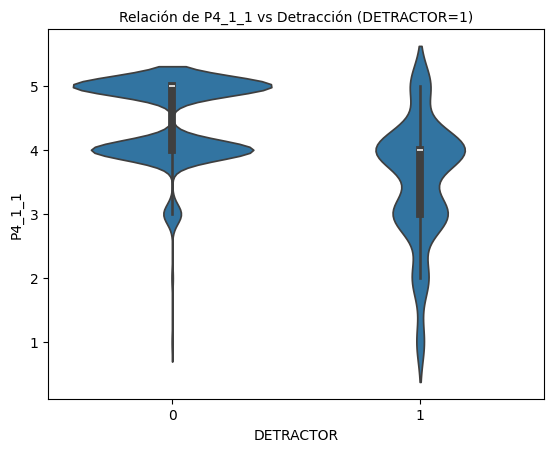

*** Prueba t para P4_1_1 ***
Estadístico t: -19.55207
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.462852
1    3.521912
Name: P4_1_1, dtype: float64




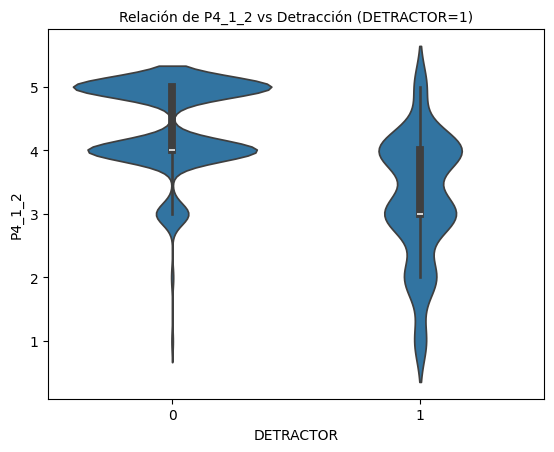

*** Prueba t para P4_1_2 ***
Estadístico t: -21.98963
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.390265
1    3.250996
Name: P4_1_2, dtype: float64




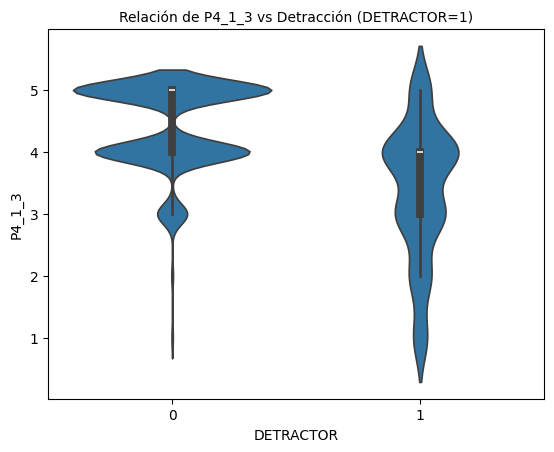

*** Prueba t para P4_1_3 ***
Estadístico t: -19.45779
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.416738
1    3.378486
Name: P4_1_3, dtype: float64




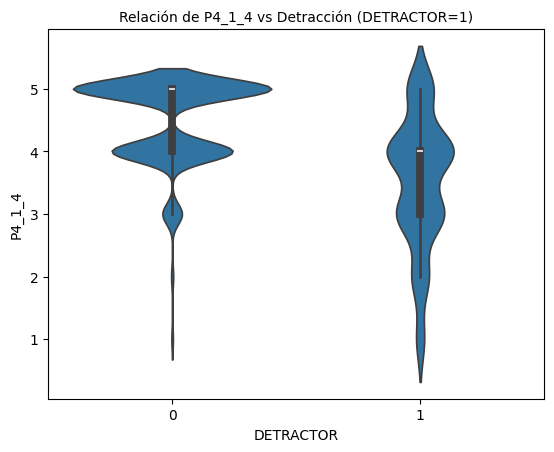

*** Prueba t para P4_1_4 ***
Estadístico t: -18.73156
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.497011
1    3.521912
Name: P4_1_4, dtype: float64




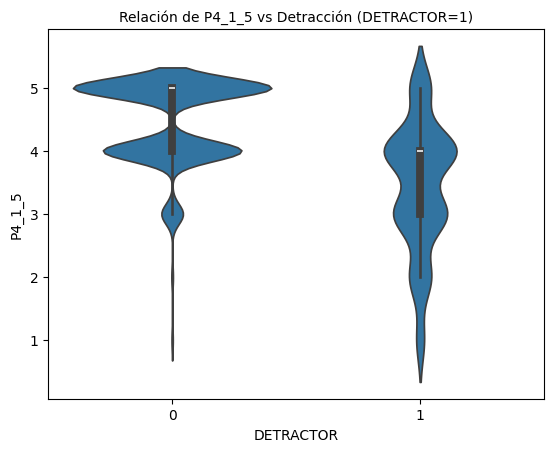

*** Prueba t para P4_1_5 ***
Estadístico t: -20.29273
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.470538
1    3.438247
Name: P4_1_5, dtype: float64




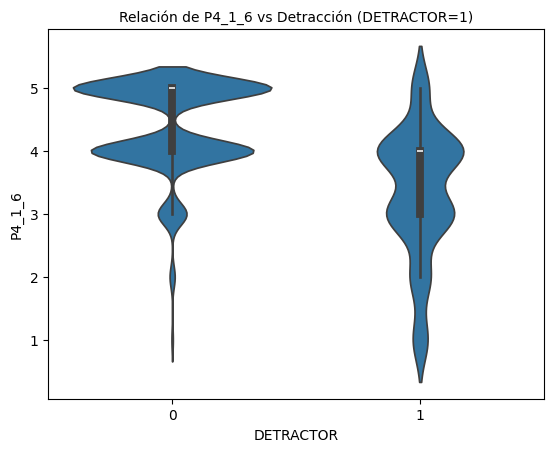

*** Prueba t para P4_1_6 ***
Estadístico t: -19.57286
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.391973
1    3.342629
Name: P4_1_6, dtype: float64




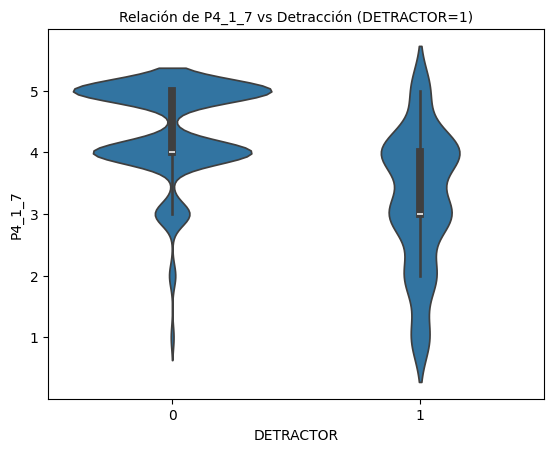

*** Prueba t para P4_1_7 ***
Estadístico t: -19.56257
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.357814
1    3.231076
Name: P4_1_7, dtype: float64




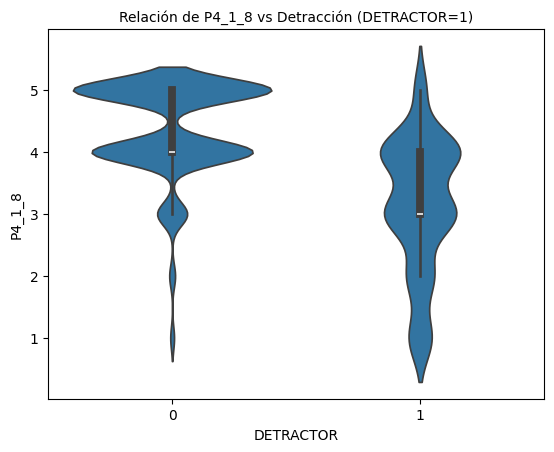

*** Prueba t para P4_1_8 ***
Estadístico t: -21.28555
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.364646
1    3.143426
Name: P4_1_8, dtype: float64




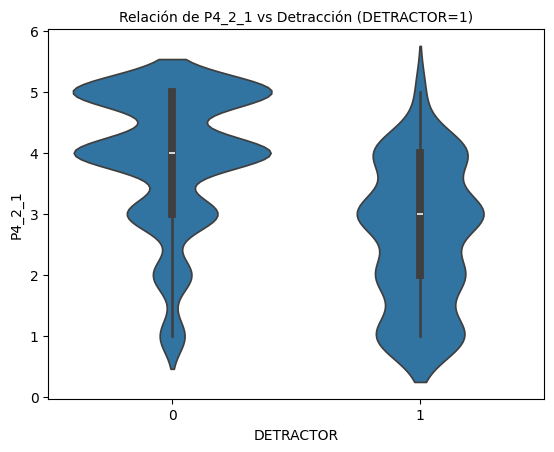

*** Prueba t para P4_2_1 ***
Estadístico t: -16.85282
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    3.921435
1    2.625498
Name: P4_2_1, dtype: float64




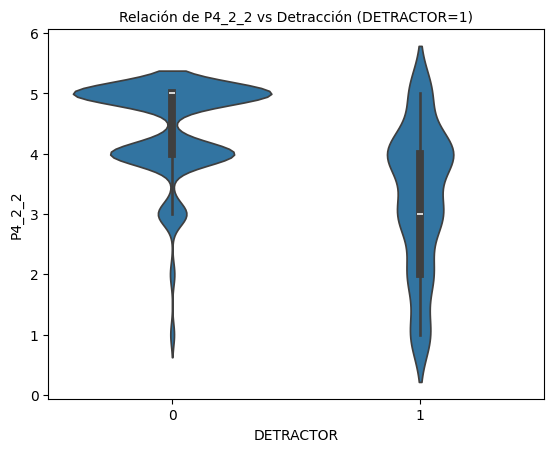

*** Prueba t para P4_2_2 ***
Estadístico t: -19.37517
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.418446
1    3.258964
Name: P4_2_2, dtype: float64




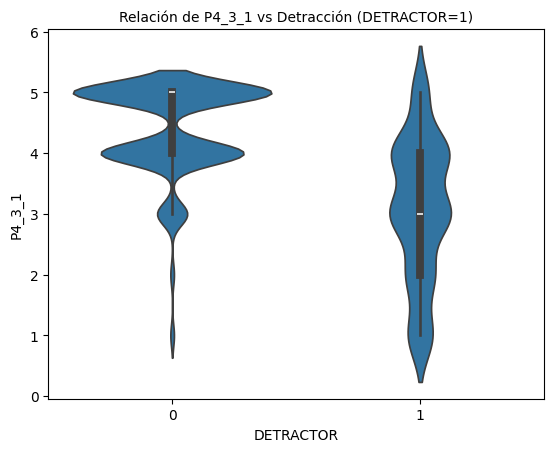

*** Prueba t para P4_3_1 ***
Estadístico t: -22.80765
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.397950
1    3.067729
Name: P4_3_1, dtype: float64




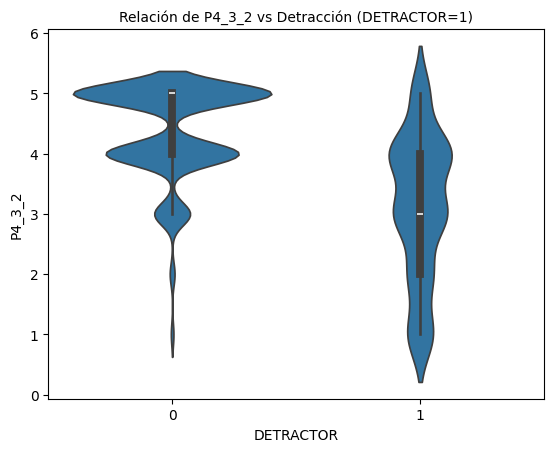

*** Prueba t para P4_3_2 ***
Estadístico t: -21.20558
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.387703
1    3.123506
Name: P4_3_2, dtype: float64




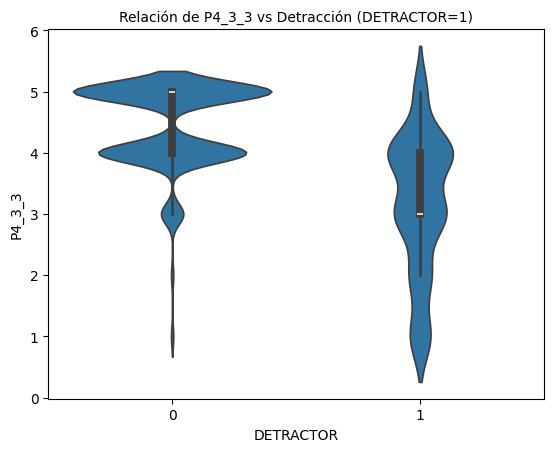

*** Prueba t para P4_3_3 ***
Estadístico t: -23.46244
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.441503
1    3.163347
Name: P4_3_3, dtype: float64




In [23]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_DISTANCIA, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_DISTANCIA, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.839
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.94      0.86      0.90       239
           1       0.50      0.72      0.59        46

    accuracy                           0.84       285
   macro avg       0.72      0.79      0.74       285
weighted avg       0.87      0.84      0.85       285



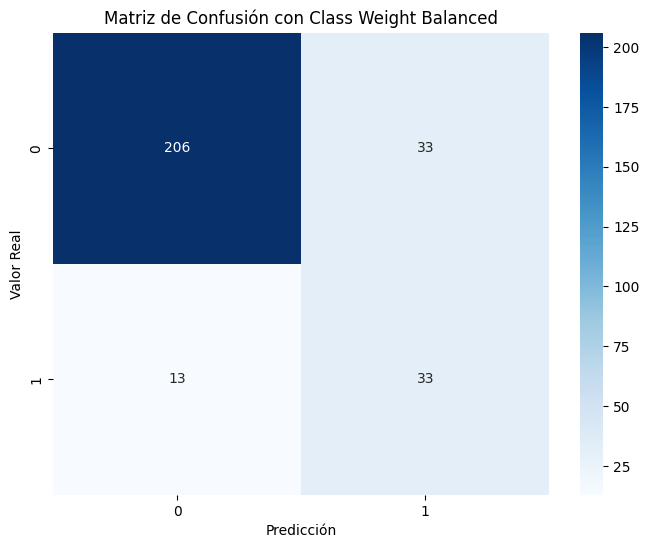

In [24]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.2, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**4.1.2 METODOLOGÍA DE LA ENSEÑANZA TEÓRICA/PRÁCTICA**

**4.1.8 EL SEGUIMIENTO DEL DESEMPEÑO DEL ESTUDIANTE ACOMPAÑADO DE RETROALIMENTACIÓN CONSTRUCTIVA SOBRE TRABAJOS, PROYECTOS Y ENTREGABLES**

**4.3.1 FLEXIBILIDAD PARA LA ELECCIÓN DE ASIGNATURAS DEL PLAN DE ESTUDIOS**

**4.2.1 CONFORMACIÓN DE GRUPOS PARA DESARROLLO DE CLASES**

  0%|          | 0/285 [00:00<?, ?it/s]

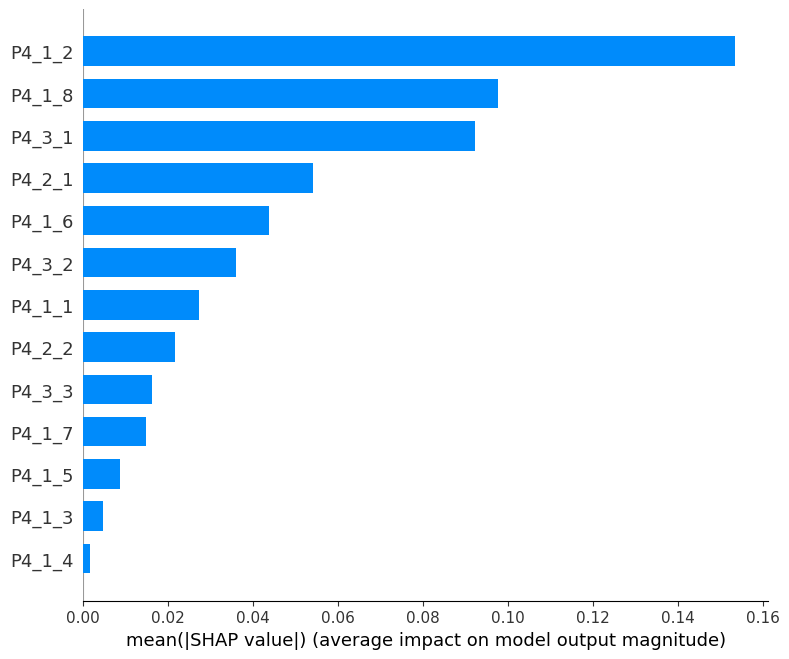

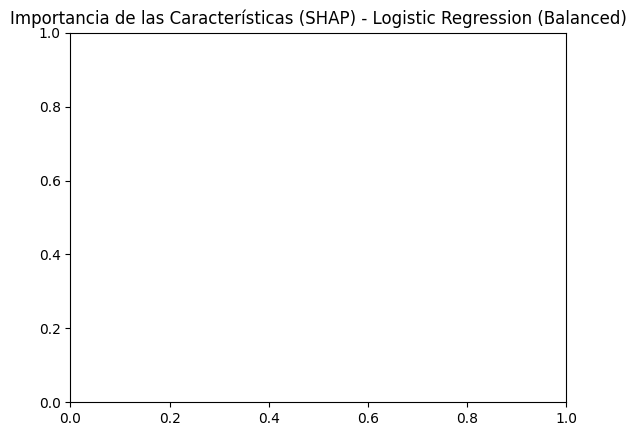

In [25]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

**Si ves puntos rojos en el lado izquierdo y azules en el derecho esto significa valores altos de la característica disminuyen la probabilidad de ser detractor y valores bajos la aumentan**

  0%|          | 0/285 [00:00<?, ?it/s]

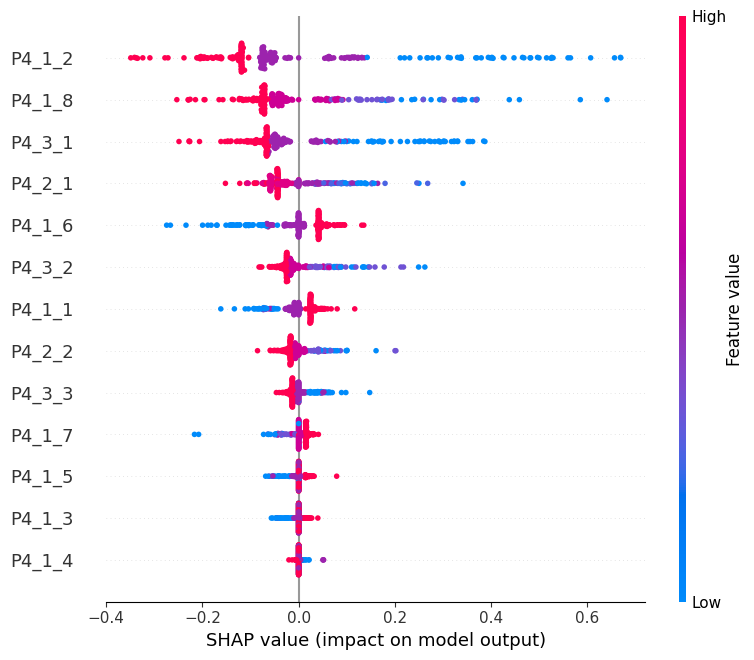

In [26]:
explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)

# **Análisis de los factores de Satisfacción con la Imagen y Comunicación de la universidad**

**P26. ¿QUÉ TAN SATISFECHO TE ENCUENTRAS CON CADA UNO DE LOS ASPECTOS DE LA COMUNICACIÓN E IMAGEN   DE LA UNIVERSIDAD CONTINENTAL?**

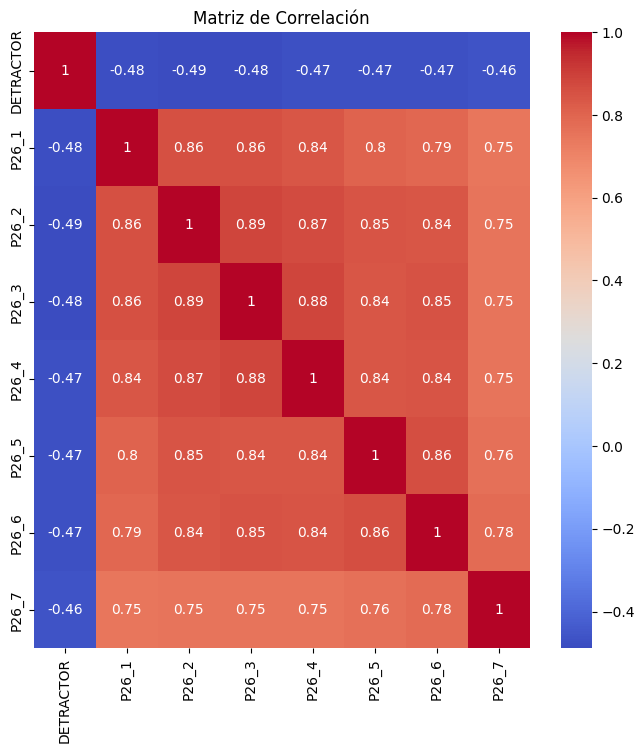

In [ ]:
copia = X = estudiantes_DISTANCIA[['DETRACTOR','P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
plt.figure(figsize=(8, 8))
sns.heatmap(copia.corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [ ]:
X = estudiantes_DISTANCIA[['P26_1','P26_2','P26_3','P26_4','P26_5','P26_6','P26_7']]
y = estudiantes_DISTANCIA['DETRACTOR']
XCopia = X.copy()

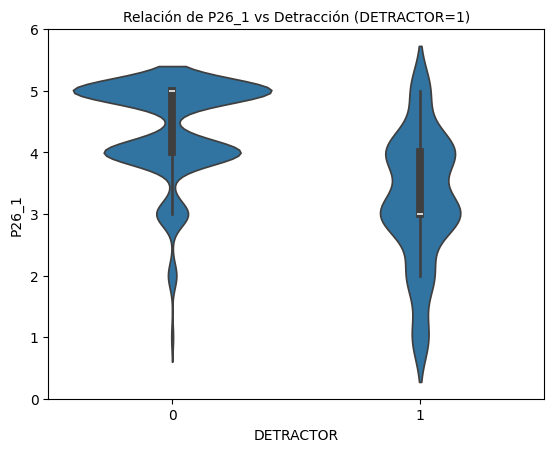

*** Prueba t para P26_1 ***
Estadístico t: -17.56369
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.383626
1    3.226804
Name: P26_1, dtype: float64




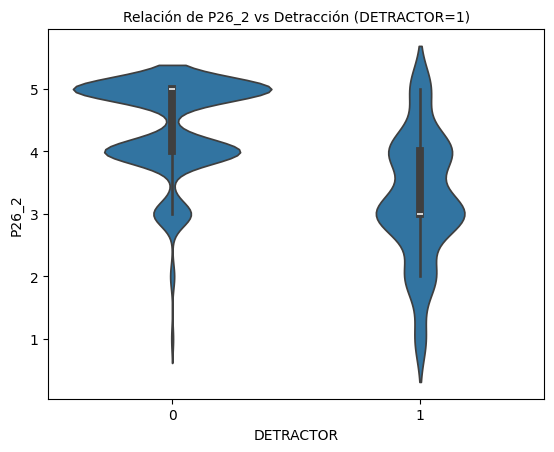

*** Prueba t para P26_2 ***
Estadístico t: -18.11746
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.390643
1    3.242268
Name: P26_2, dtype: float64




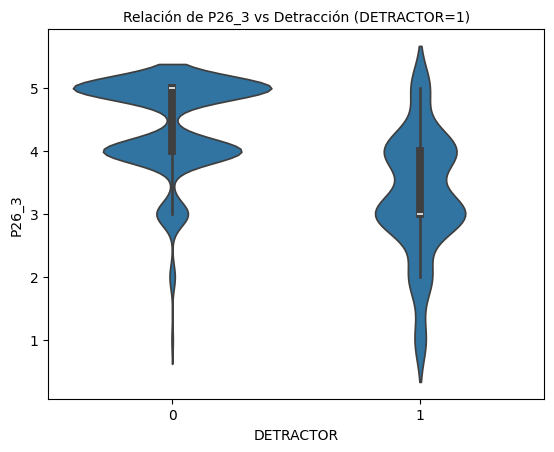

*** Prueba t para P26_3 ***
Estadístico t: -17.87478
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.405848
1    3.298969
Name: P26_3, dtype: float64




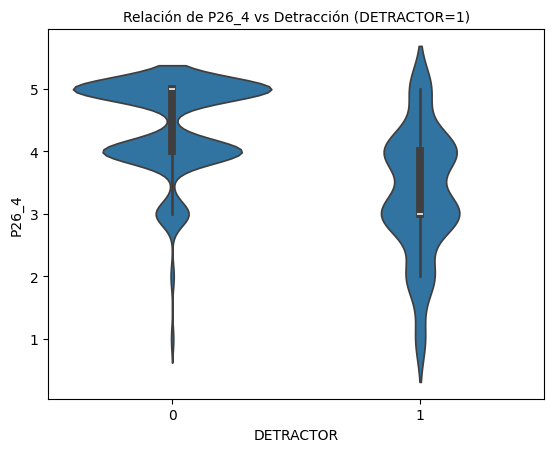

*** Prueba t para P26_4 ***
Estadístico t: -17.29746
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.405848
1    3.324742
Name: P26_4, dtype: float64




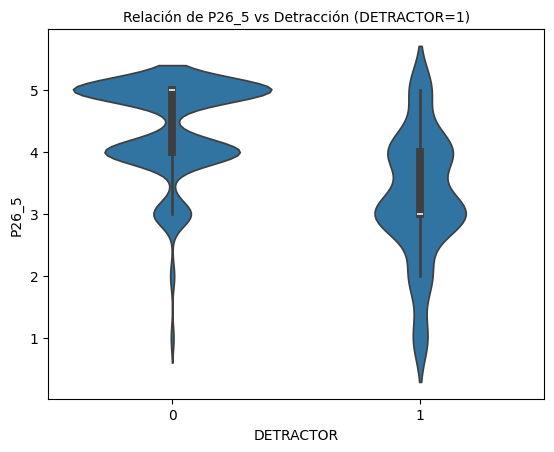

*** Prueba t para P26_5 ***
Estadístico t: -17.28794
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.383626
1    3.262887
Name: P26_5, dtype: float64




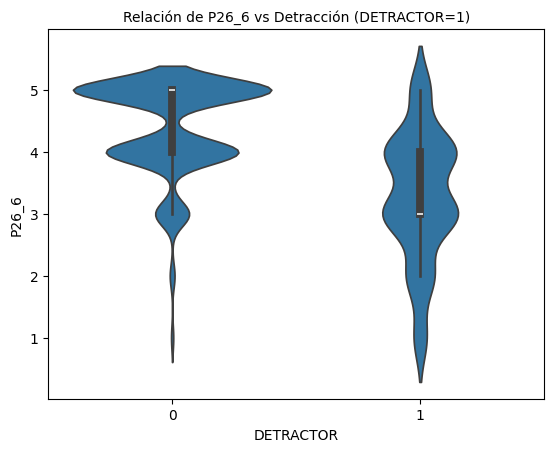

*** Prueba t para P26_6 ***
Estadístico t: -17.29612
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.398830
1    3.283505
Name: P26_6, dtype: float64




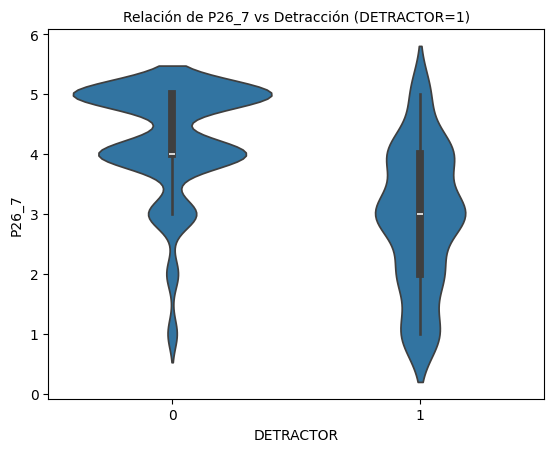

*** Prueba t para P26_7 ***
Estadístico t: -16.95034
Valor p: 0.00000
Se rechaza la hipótesis nula. Las medias son significativamente diferentes.
DETRACTOR
0    4.239766
1    2.932990
Name: P26_7, dtype: float64




In [ ]:
for column in X.columns:
    title = f"Relación de {column} vs Detracción (DETRACTOR=1)"
    ml.analisis_variable_violin(estudiantes_DISTANCIA, "DETRACTOR", column, title)
    ml.prueba_t(estudiantes_DISTANCIA, 'DETRACTOR', column, 1, 0, XCopia)

Precisión del modelo con class_weight='balanced': 0.819
Reporte de clasificación con class_weight='balanced':
              precision    recall  f1-score   support

           0       0.92      0.85      0.88       170
           1       0.52      0.70      0.60        40

    accuracy                           0.82       210
   macro avg       0.72      0.77      0.74       210
weighted avg       0.85      0.82      0.83       210



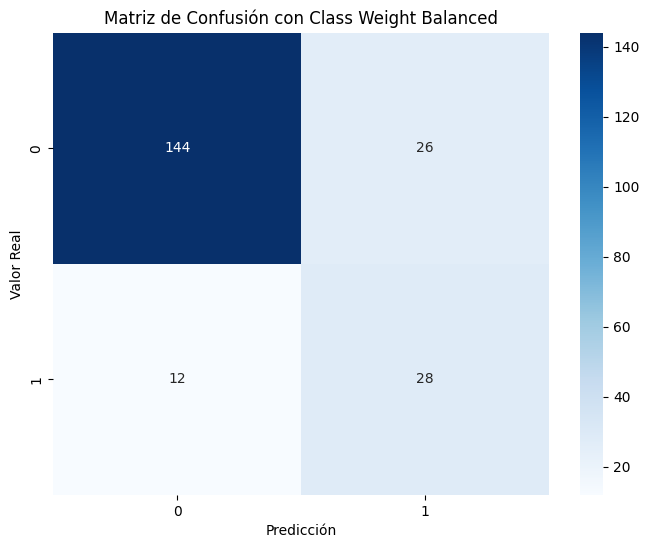

In [ ]:
# Modelo de Regresión Logística con class_weight='balanced'
# Esto asignará automáticamente pesos inversamente proporcionales a las frecuencias de clase.

X_train, X_test, y_train, y_test = train_test_split(XCopia, y, test_size=0.2, random_state=42)

model_balanced = LogisticRegression(solver='liblinear', max_iter=300, random_state=50, class_weight='balanced')

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
report_balanced = classification_report(y_test, y_pred_balanced)

print(f'Precisión del modelo con class_weight=\'balanced\': {accuracy_balanced:.3f}')
print(f'Reporte de clasificación con class_weight=\'balanced\':\n{report_balanced}')

# Graficar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión con Class Weight Balanced')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

**26.7 MONTO DE LA PENSIÓN**

**26.2 COMUNICACIÓN REALIZADA POR LA UNIVERSIDAD A LOS ESTUDIANTES A TRAVÉS DE BLOG, REDES SOCIALES Y OTROS CANALES**

**26.3 CONTENIDO DE LA COMUNICACIÓN DIRIGIDA A LOS ESTUDIANTES**

  0%|          | 0/210 [00:00<?, ?it/s]

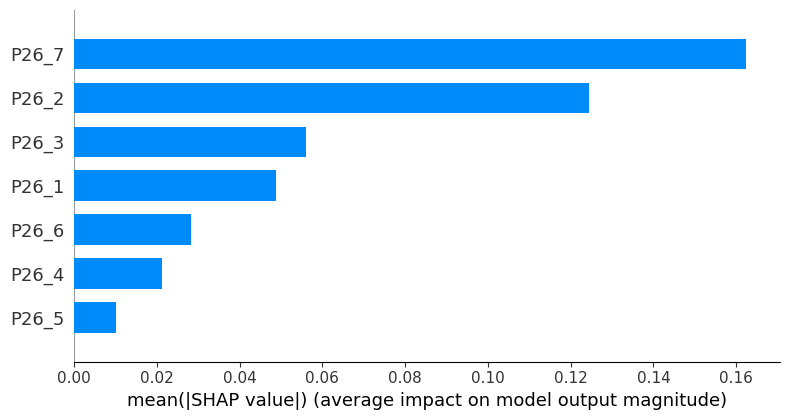

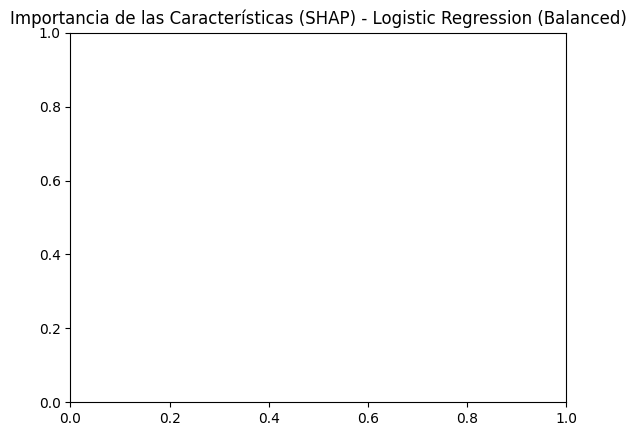

In [ ]:
import shap

explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns, plot_type="bar")
plt.title('Importancia de las Características (SHAP) - Logistic Regression (Balanced)')
plt.show()

  0%|          | 0/210 [00:00<?, ?it/s]

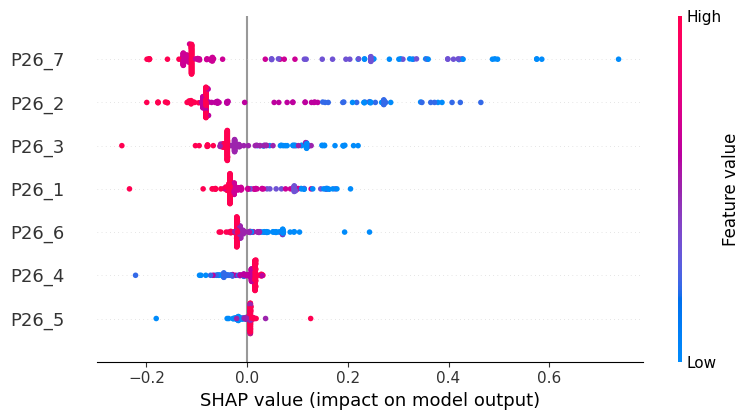

In [ ]:
explainer = shap.KernelExplainer(model_balanced.predict, X_train)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=XCopia.columns)